In [6]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
path = 'data/pdebench_burgers_core.npz'

In [62]:
d = np.load(path)
for key in d.files:
    print(f"{key}: shape = {d[key].shape}")

train_field: shape = (240, 128)
train_target: shape = (240, 128)
train_context: shape = (240, 2)
train_coordinates: shape = (128,)
eval_128_field: shape = (60, 128)
eval_128_target: shape = (60, 128)
eval_128_context: shape = (60, 2)
eval_128_coordinates: shape = (128,)
eval_256_field: shape = (60, 256)
eval_256_target: shape = (60, 256)
eval_256_context: shape = (60, 2)
eval_256_coordinates: shape = (256,)
eval_512_field: shape = (60, 512)
eval_512_target: shape = (60, 512)
eval_512_context: shape = (60, 2)
eval_512_coordinates: shape = (512,)


Mean absolute change: 0.011718096
Maximum absolute change: 0.61344814
Change standard deviation: 0.031024555


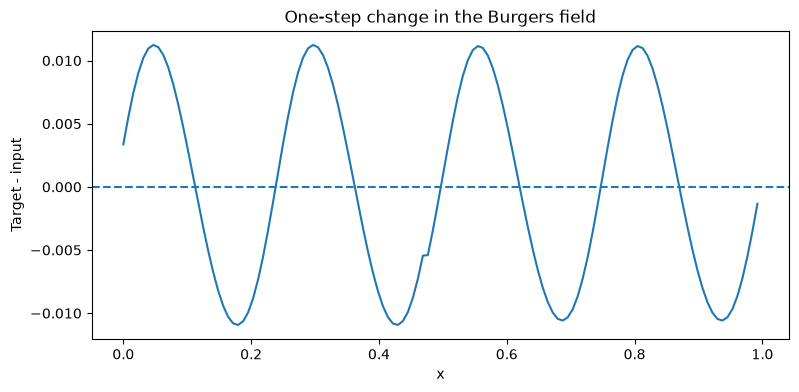

In [63]:
data = np.load('data/train.npz')
change = data['target'] - data['field']

print("Mean absolute change:", np.mean(np.abs(change)))
print("Maximum absolute change:", np.max(np.abs(change)))
print("Change standard deviation:", np.std(change))

plt.figure(figsize=(9, 4))
plt.plot(x, change[0])
plt.axhline(0, linestyle="--")
plt.xlabel("x")
plt.ylabel("Target - input")
plt.title("One-step change in the Burgers field")
plt.show()

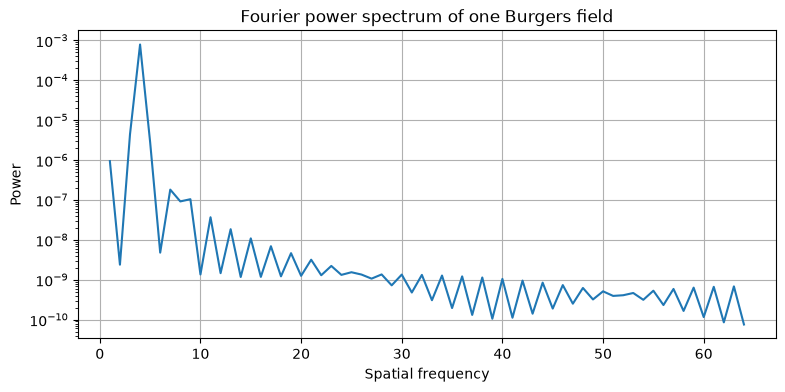

In [64]:
u = data["field"][0]
x = data["coordinates"]

dx = np.mean(np.diff(x))
freq = np.fft.rfftfreq(len(u), d=dx)
power = np.abs(np.fft.rfft(u))**2 / len(u)**2

plt.figure(figsize=(9, 4))
plt.semilogy(freq[1:], power[1:] + 1e-15)
plt.xlabel("Spatial frequency")
plt.ylabel("Power")
plt.title("Fourier power spectrum of one Burgers field")
plt.grid(True)
plt.show()

[-0.69909096 -0.68444973 -0.66973656 -0.65503603 -0.6404777  -0.62629175
 -0.6129168  -0.60120547 -0.59280276 -0.59077007 -0.6003537  -0.6290259
 -0.6834467  -0.7614808  -0.8462953  -0.91581064 -0.95915985 -0.97894806
 -0.98283    -0.9774705  -0.9671416  -0.9542422  -0.94003874 -0.9251778
 -0.90998995 -0.8946437  -0.87922746 -0.86378723 -0.84835106 -0.83293796
 -0.81756276 -0.8022398  -0.78698605 -0.77182215 -0.756775   -0.74188244
 -0.727199   -0.712802   -0.69880706 -0.68538624 -0.6727965  -0.66141975
 -0.65181416 -0.6447707  -0.64135104 -0.64284897 -0.6505886  -0.6654471
 -0.68715626 -0.71372455 -0.7415845  -0.7667095  -0.7860447  -0.7982804
 -0.8036628  -0.8033053  -0.79855293 -0.79062253 -0.7804711  -0.7687956
 -0.75608104 -0.7294961  -0.7155743  -0.70141286 -0.68709683 -0.67270327
 -0.6583201  -0.64407814 -0.6302049  -0.61712575 -0.6056546  -0.59733546
 -0.59499866 -0.6034369  -0.62945956 -0.6793562  -0.7520265  -0.8331442
 -0.90212965 -0.94716495 -0.9691914  -0.97496563 -0.97098

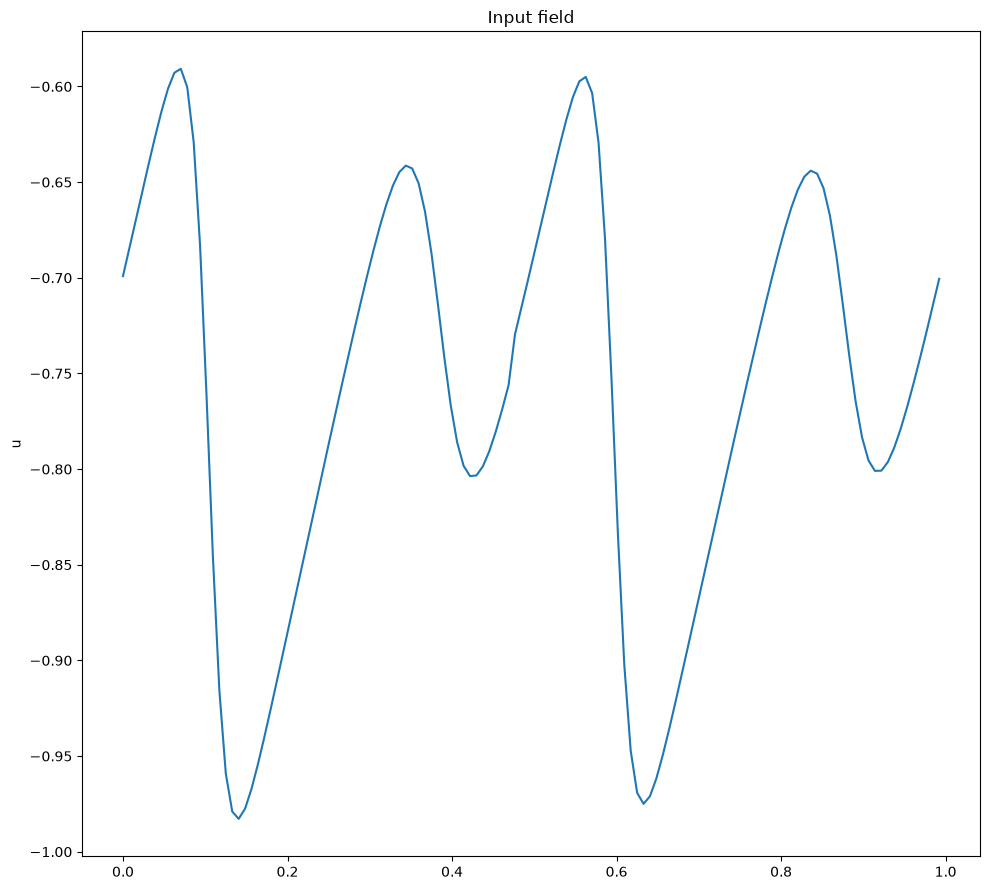

In [114]:
index = 6
x = d['eval_128_coordinates']
u = d['eval_128_field'][index]
print(u,x.shape,u.shape,len(x))

fig, axes = plt.subplots(figsize=(10, 9))
axes.plot(x, u)
axes.set_ylabel("u")
axes.set_title("Input field")
plt.tight_layout()

In [115]:
dx = 1/len(x)   #length/total points
dx

0.0078125

In [116]:
ux = np.gradient(u, dx)
ux

array([  1.8740768 ,   1.8786812 ,   1.8824768 ,   1.8725662 ,
         1.839634  ,   1.763897  ,   1.6055222 ,   1.2873001 ,
         0.66786575,  -0.4832611 ,  -2.448372  ,  -5.317951  ,
        -8.477116  , -10.42231   ,  -9.87711   ,  -7.2233315 ,
        -4.0407944 ,  -1.5148888 ,   0.09456253,   1.004055  ,
         1.4866104 ,   1.7345848 ,   1.8601227 ,   1.9231224 ,
         1.9541817 ,   1.9687996 ,   1.9748154 ,   1.9760895 ,
         1.9743538 ,   1.9704514 ,   1.9646835 ,   1.9569092 ,
         1.9467278 ,   1.933506  ,   1.9161415 ,   1.8928642 ,
         1.8611488 ,   1.8170853 ,   1.7546082 ,   1.6646767 ,
         1.5338554 ,   1.3428688 ,   1.0655403 ,   0.6696396 ,
         0.12298965,  -0.5912018 ,  -1.4462814 ,  -2.340332  ,
        -3.089756  ,  -3.483406  ,  -3.391037  ,  -2.8454552 ,
        -2.0205383 ,  -1.1275558 ,  -0.32159424,   0.32703018,
         0.8116989 ,   1.157238  ,   1.3969231 ,   1.5609627 ,
         2.5151672 ,   2.59243   ,   1.797329  ,   1.82

In [117]:
uxx = (np.roll(u, -1) - 2 * u + np.roll(u, 1)) / (dx ** 2)
first_term = -u * ux
secondd_term = (0.01) * uxx
rhs_est = first_term + secondd_term
rhs_est

array([ 3.4744177 ,  1.2976499 ,  1.2586932 ,  1.2032976 ,  1.1172388 ,
        0.9718333 ,  0.7114929 ,  0.23184204, -0.6477494 , -2.1887188 ,
       -4.59735   , -7.563791  , -9.662456  , -9.047287  , -5.85234   ,
       -2.3281436 , -0.01553345,  1.1230865 ,  1.6070502 ,  1.7956235 ,
        1.8589152 ,  1.8688762 ,  1.8563023 ,  1.8327947 ,  1.804233  ,
        1.7728488 ,  1.7402377 ,  1.7062567 ,  1.6711658 ,  1.6350528 ,
        1.5976974 ,  1.5585628 ,  1.5173309 ,  1.473192  ,  1.4247657 ,
        1.3700151 ,  1.3065017 ,  1.2293432 ,  1.1320701 ,  1.0047843 ,
        0.8332323 ,  0.59801435,  0.27475888, -0.16196647, -0.7268138 ,
       -1.4026902 , -2.1073012 , -2.6797695 , -2.9192681 , -2.6978135 ,
       -2.0666544 , -1.233034  , -0.4250499 ,  0.22274572,  0.6819568 ,
        0.9827734 ,  1.1688681 ,  1.2788349 ,  1.3399553 ,  1.3703053 ,
        4.1741896 , -0.18355882,  1.32539   ,  1.3036889 ,  1.2751863 ,
        1.2372148 ,  1.182923  ,  1.0985173 ,  0.95697606,  0.70

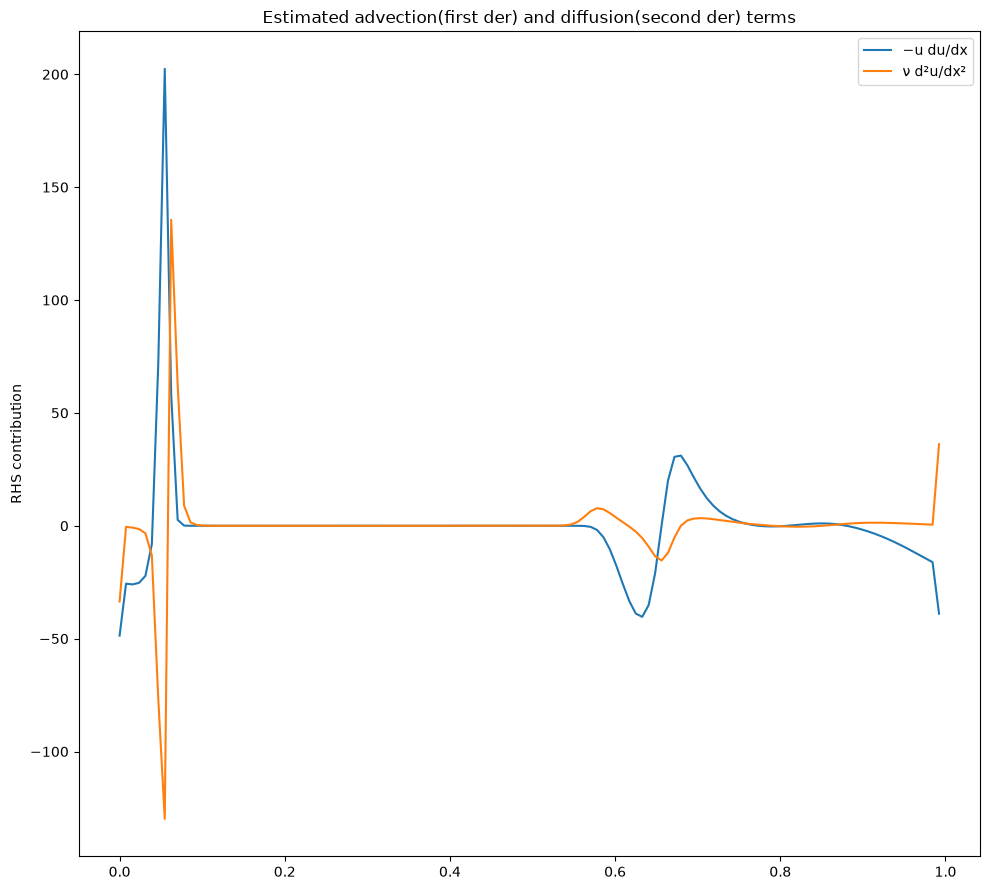

In [121]:
fig, axes = plt.subplots(figsize=(10, 9))
axes.plot(x, advection_term, label="−u du/dx")
axes.plot(x, diffusion_term, label="ν d²u/dx²")
axes.set_ylabel("RHS contribution")
axes.set_title("Estimated advection(first der) and diffusion(second der) terms")
axes.legend()
plt.tight_layout()

To plot Net instantaneous change

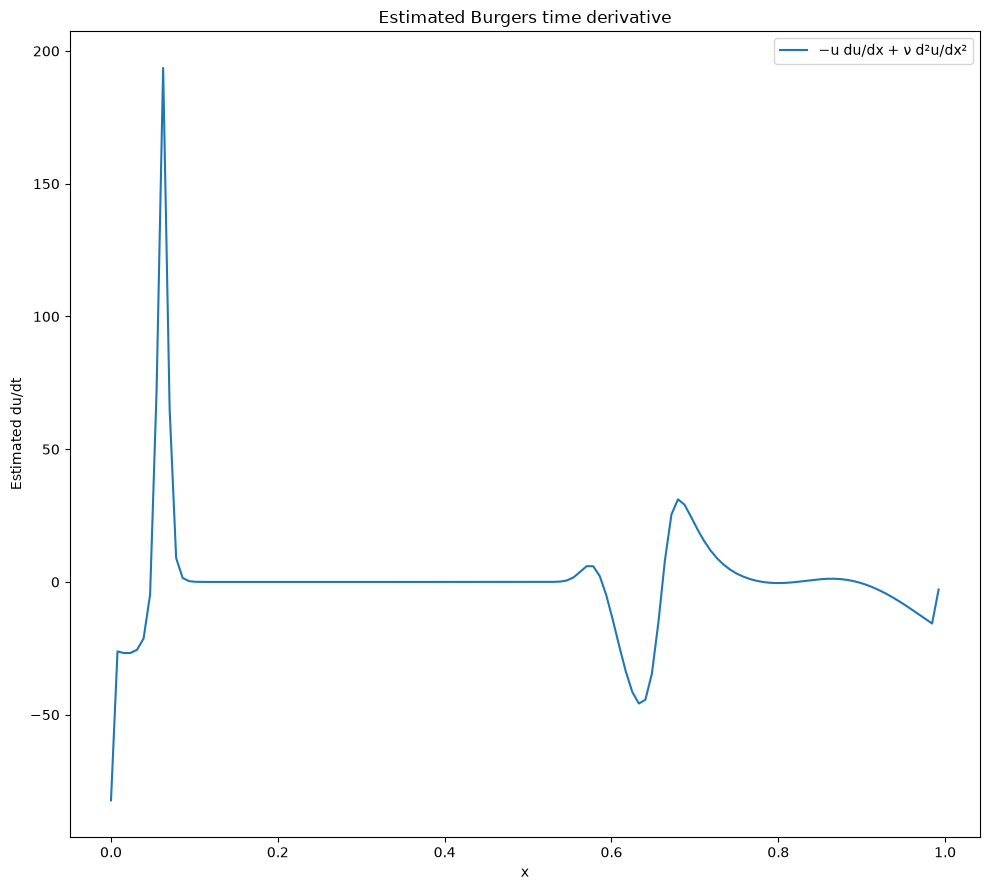

In [120]:
fig, axes = plt.subplots(figsize=(10, 9))
axes.plot(x, rhs_estimate,
             label="−u du/dx + ν d²u/dx²")
axes.set_xlabel("x")
axes.set_ylabel("Estimated du/dt")
axes.set_title("Estimated Burgers time derivative")
axes.legend()
plt.tight_layout()